# Simulated twins, one time point: covariance decomposition and inference scenarios

This tutorial shows how to score a pair of genes with `infer_with_twinfer` when twins are measured at **one time point**, how to read the three z-scores and the inference scenario it reports, and how to draw the result as a network. The direction of regulation needs two time points: see [`inference_simulation_two_time_points.ipynb`](inference_simulation_two_time_points.ipynb).

**What TwINFER uses.** Sister cells ("twins") come from the same mother cell. Right after division they share their molecules and the cell state they inherited; with time, each sister's expression drifts away from the other's. Because of this, the correlation of two genes across cells can be split into a part the twins share and a part that differs between twins. The two parts tell apart two reasons why two genes are correlated:

* **regulation**: X acts on Y in every cell, so the correlation shows up in the twin differences too;
* **heterogeneity**: cells sit in different states (for example two cell types) that set both genes. Twins sit in the same state, so the correlation is shared by twins and is absent from their differences.

**The three z-scores** (one gene pair, N twin pairs):

| z-score | measures | significant when |
|---|---|---|
| `z_rho` | the expression correlation of X and Y over all cells (Spearman) | \|z\| > 1.96 |
| `z_rho_s` | the twin-shared part: X in one sister against Y in the other sister | \|z\| > 2.326 |
| `z_rho_delta` | the correlation of the twin differences (X in sister 1 minus sister 2, the same for Y) | \|z\| > 1.96 |

All three are analytic (no shuffling) and use N = the number of twin pairs. For real lineage-tracing data (clones of any size, many gene pairs, Benjamini-Hochberg correction), see [`inference_real_data_lineage_tracing.ipynb`](inference_real_data_lineage_tracing.ipynb).

**The four inference scenarios** follow from these z-scores:

| scenario | z_rho | z_rho_s | z_rho_delta | reading |
|---|---|---|---|---|
| 1 nothing | not significant | | | no correlation |
| 2 regulation | significant | not significant | | correlation not shared by twins |
| 3 regulation + heterogeneity | significant | significant | significant | shared part and a twin-difference part |
| 4 heterogeneity | significant | significant | not significant | correlation only through a shared state |

**Data used here.** A simulated two-gene network in which gene 1 activates gene 2 (A → B), with 6,000 twin pairs followed for 48 hours after division. The file ships with the repository in `simulation_example_output_data/`.

## 1. Setup

Install the package once from the repository root (`pip install -e package/`, see the README). Then:

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from twinfer.inference.covariance_decomposition_z_scores import (
    INFERENCE_SCENARIOS,
    classify_inference_scenario,
    infer_with_twinfer,
)
from twinfer.plotting.network_plots import network_from_scenarios, plot_grn
from twinfer.utils.paths import get_repo_root

data_file = get_repo_root() / "simulation_example_output_data" / "df_rows_0_0_20112025_222419_ncells_6000_A_to_B_4e702629.csv"

## 2. The input table

`infer_with_twinfer` reads a long table with one row per cell and time point:

* `clone_id`: the twin pair (the mother cell);
* `replicate`: 1 or 2, which sister;
* `time_step`: hours after division;
* one column per measured quantity. The simulation also stores protein counts; TwINFER uses the mRNA columns, as in real data.

In [2]:
table = pd.read_csv(data_file)
print(f"{table['clone_id'].nunique()} twin pairs, time steps {table['time_step'].min()}-{table['time_step'].max()} h")
table.head()

6000 twin pairs, time steps 0-48 h


,cell_id,time_step,gene_1_mRNA,gene_1_protein,gene_2_mRNA,gene_2_protein,replicate,clone_id
0,0,0,0,15158,3,35482,1,0
1,0,1,0,14937,2,36274,1,0
2,0,2,0,14723,4,37046,1,0
3,0,3,0,14490,4,38719,1,0
4,0,4,1,14483,4,40448,1,0


## 3. Score the gene pair at one time point

We use the mRNA counts 20 hours after division. With one time point in `time_points`, the function compares the two sisters of every twin pair at that time.

In [3]:
genes = ["gene_1_mRNA", "gene_2_mRNA"]
result = infer_with_twinfer(table, genes, time_points=[20])
result[["gene_x", "gene_y", "N", "z_rho", "z_rho_s", "z_rho_delta", "inference_scenario"]]

,gene_x,gene_y,N,z_rho,z_rho_s,z_rho_delta,inference_scenario
0,gene_1_mRNA,gene_2_mRNA,6000,7.216797,0.707215,4.969163,2


`z_rho` and `z_rho_delta` are significant, `z_rho_s` is not. The pair is called scenario 2, regulation:

* `z_rho` is large: the two genes are correlated;
* `z_rho_s` (0.7) is below 2.326: what sister 1 expresses of gene 1 tells little about what sister 2 expresses of gene 2, so the correlation is not carried by a shared state;
* `z_rho_delta` is large: when one sister has more gene 1 than its twin, it also has more gene 2. Regulation acts inside each cell.

The table holds the quantities the z-scores are built from. `S` is the Spearman correlation over all cells. `C` is its twin-shared part and `U = S - C` the unshared part. `h_x`, `h_y` are the sister correlations of each gene (how alike the twins are). `z_rho` splits exactly into a shared and an unshared contribution, `z_rho = A_s + A_u`:

In [4]:
row = result.iloc[0]
print(f"S = {row.S:.4f} = C + U = {row.C:.4f} + {row.U:.4f}")
print(f"z_rho = {row.z_rho:.3f} = A_s + A_u = {row.A_s:.3f} + {row.A_u:.3f}")
print(f"sister correlations: h_x = {row.h_x:.3f}, h_y = {row.h_y:.3f}")

S = 0.0659 = C + U = 0.0065 + 0.0595
z_rho = 7.217 = A_s + A_u = 0.709 + 6.508
sister correlations: h_x = 0.015, h_y = 0.128


The scenario can also be computed from any three z-scores with `classify_inference_scenario` (thresholds can be changed with `thresholds=(z_rho, z_rho_s, z_rho_delta)`):

In [5]:
scenario = classify_inference_scenario(row.z_rho, row.z_rho_s, row.z_rho_delta)[0]
print("scenario", scenario, INFERENCE_SCENARIOS[scenario])

scenario 2 regulation


## 4. How many twin pairs are needed

For a fixed correlation, the z-scores grow with the square root of the number of twin pairs. Scoring one random subset of twin pairs per size at 20 hours:

In [6]:
rng = np.random.default_rng(0)
twin_pairs = table["clone_id"].unique()          # clone_id = twin pair
rows = []
for n in [100, 250, 500, 1000, 3000, 6000]:
    chosen = rng.choice(twin_pairs, size=n, replace=False)
    rows.append(infer_with_twinfer(table[table["clone_id"].isin(chosen)], genes, time_points=[20]))
pd.concat(rows)[["N", "z_rho", "z_rho_s", "z_rho_delta", "inference_scenario"]]

,N,z_rho,z_rho_s,z_rho_delta,inference_scenario
0,100,2.132603,-0.050308,1.805744,2
0,250,0.957914,-1.731536,1.850387,1
0,500,1.967992,1.000107,0.774551,2
0,1000,2.331536,0.196850,1.552705,2
0,3000,5.452194,1.145131,3.263425,2
0,6000,7.216797,0.707215,4.969163,2


The correlation in this example is weak (Spearman 0.07 at 20 hours), so with fewer than about 1,000 twin pairs it is not reliably detected; each subset is a single random draw, so the small sizes scatter.

## 5. Draw the result as a network

`network_from_scenarios` turns the result table into the inputs of `plot_grn`:

* scenario 2 or 3 (regulation): **solid** edge;
* scenario 4 (heterogeneity, a shared state): **dashed** edge;
* scenario 1: no edge;
* colour = `z_rho`.

With one time point there is no direction, so edges are drawn without arrowheads (with two time points they get one, see the next tutorial). $g_1$ and $g_2$ below are gene 1 and gene 2, scored 20 hours after division (the `result` of section 3):

,source,target,weight,inference_scenario,line_style,directed
0,gene_1_mRNA,gene_2_mRNA,7.216797,2,solid,False


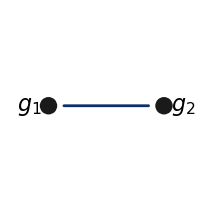

In [7]:
labels = {"gene_1_mRNA": "$g_1$", "gene_2_mRNA": "$g_2$"}
positions = {0: (0.2, 0.5), 1: (0.8, 0.5)}

plot_kwargs, edges = network_from_scenarios(result)
plot_kwargs["node_labels"] = [labels[g] for g in plot_kwargs["node_labels"]]
fig, ax = plt.subplots(figsize=(4.5, 2.5))
plot_grn(**plot_kwargs, ax=ax, fixed_pos=positions, show_colorbar=False, figsize=(8, 8))   # figsize sets line scale
edges

The pair is called regulation (scenario 2), so the edge is solid. The same calls work for any number of genes: pass all gene columns to `infer_with_twinfer` and the whole result table to `network_from_scenarios`. `plot_grn(**plot_kwargs)` draws the nodes on a circle when `fixed_pos` is not given.

## Summary

| step | call |
|---|---|
| score gene pairs at one time point | `infer_with_twinfer(table, genes, time_points=[t])` |
| add the direction (next tutorial) | `infer_with_twinfer(table, genes, time_points=[t_a, t_b])` |
| scenario from z-scores | `classify_inference_scenario(z_rho, z_rho_s, z_rho_delta)` |
| network figure | `plot_grn(**network_from_scenarios(result)[0])` |

Next: [`inference_simulation_two_time_points.ipynb`](inference_simulation_two_time_points.ipynb) (direction of regulation) and [`inference_real_data_lineage_tracing.ipynb`](inference_real_data_lineage_tracing.ipynb) (real data). The analyses of the paper that use these functions are in `paper_analysis/` (for example `heterogeneity_vs_regulation/` scores single-state, two-state and drifting simulations the same way).